### Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import json
import re
import os
from datasets import load_dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### Load Both Corpora

In [4]:
!pip install -q datasets==4.4.1 huggingface_hub==1.5.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 15.2 MB/s eta 0:00:00


In [17]:
# --- Roman Urdu ---
ru_df = pd.read_csv("/content/Roman_Urdu_DataSet.csv", encoding="utf-8", on_bad_lines="skip")
ru_df = ru_df[["Comment"]].dropna()
ru_df.columns = ["text"]
ru_lines = ru_df["text"].tolist()
ru_lines = [str(t).strip() for t in ru_lines if len(str(t).split()) >= 3]
print(f"Roman Urdu sentences: {len(ru_lines)}")

# --- English ---
import urllib.request

# Download WikiText-2 directly as a raw text file
url = "https://raw.githubusercontent.com/pytorch/examples/master/word_language_model/data/wikitext-2/train.txt"
urllib.request.urlretrieve(url, "/content/wikitext2_train.txt")

with open("/content/wikitext2_train.txt", "r", encoding="utf-8") as f:
    raw_lines = f.readlines()

en_lines = [line.strip() for line in raw_lines if len(line.strip().split()) >= 5]
print(f"English sentences: {len(en_lines)}")

Roman Urdu sentences: 13165
English sentences: 23029


### Exploratory Data Analysis

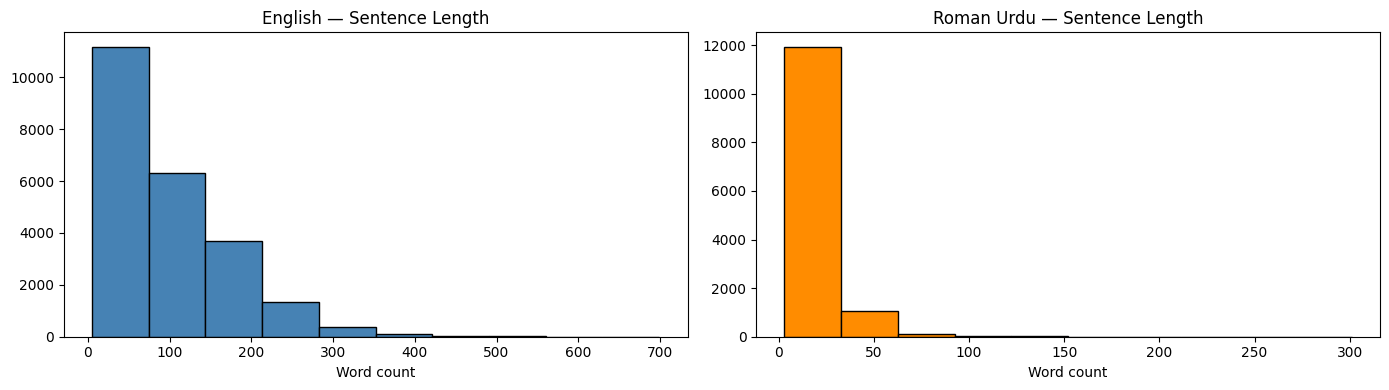

English   — mean: 89.0, median: 78.0, max: 699
Roman Urdu — mean: 15.8, median: 12.0, max: 301


In [18]:
ru_lengths = [len(t.split()) for t in ru_lines]
en_lengths = [len(t.split()) for t in en_lines]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(en_lengths, bins=10, color="steelblue", edgecolor="black")
axes[0].set_title("English — Sentence Length")
axes[0].set_xlabel("Word count")
axes[1].hist(ru_lengths, bins=10, color="darkorange", edgecolor="black")
axes[1].set_title("Roman Urdu — Sentence Length")
axes[1].set_xlabel("Word count")
plt.tight_layout(); plt.show()

print(f"English   — mean: {np.mean(en_lengths):.1f}, median: {np.median(en_lengths):.1f}, max: {max(en_lengths)}")
print(f"Roman Urdu — mean: {np.mean(ru_lengths):.1f}, median: {np.median(ru_lengths):.1f}, max: {max(ru_lengths)}")

### Preprocessing & Vocab Building

In [26]:
def clean_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z\s]", "", text)   # keep only letters + spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

def build_vocab(lines, max_vocab=10000):
    all_words = []
    for line in lines:
        all_words.extend(clean_text(line).split())
    counter = Counter(all_words)
    vocab = ["<PAD>", "<UNK>"] + [w for w, _ in counter.most_common(max_vocab - 2)]
    word2idx = {w: i for i, w in enumerate(vocab)}
    idx2word = {i: w for w, i in word2idx.items()}
    return vocab, word2idx, idx2word

def make_sequences(lines, word2idx, seq_len=10):
    sequences = []
    for line in lines:
        tokens = [word2idx.get(w, word2idx["<UNK>"]) for w in clean_text(line).split()]
        for i in range(seq_len, len(tokens)):
            seq   = tokens[i - seq_len : i]
            label = tokens[i]
            sequences.append((seq, label))
    return sequences

SEQ_LEN = 10

# English
en_vocab, en_word2idx, en_idx2word = build_vocab(en_lines, max_vocab=5000)
en_sequences = make_sequences(en_lines, en_word2idx, SEQ_LEN)

# Roman Urdu
ru_vocab, ru_word2idx, ru_idx2word = build_vocab(ru_lines, max_vocab=5000)
ru_sequences = make_sequences(ru_lines, ru_word2idx, SEQ_LEN)

print(f"English  — vocab: {len(en_vocab):,} | sequences: {len(en_sequences):,}")
print(f"Roman Urdu — vocab: {len(ru_vocab):,} | sequences: {len(ru_sequences):,}")

# Save vocabs
os.makedirs("../data/processed", exist_ok=True)
with open("../data/processed/english_vocab.json", "w") as f:
    json.dump({"word2idx": en_word2idx, "idx2word": en_idx2word}, f)
with open("../data/processed/roman_urdu_vocab.json", "w") as f:
    json.dump({"word2idx": ru_word2idx, "idx2word": ru_idx2word}, f)

print("Vocabs saved.")

English  — vocab: 5,000 | sequences: 1,512,410
Roman Urdu — vocab: 5,000 | sequences: 93,257
Vocabs saved.


### PyTorch Dataset & DataLoader

In [27]:
class TextDataset(Dataset):
    def __init__(self, sequences):
        self.sequences = sequences

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        seq, label = self.sequences[idx]
        return torch.tensor(seq, dtype=torch.long), torch.tensor(label, dtype=torch.long)

en_dataset = TextDataset(en_sequences)
ru_dataset = TextDataset(ru_sequences)

en_loader = DataLoader(en_dataset, batch_size=128, shuffle=True)
ru_loader = DataLoader(ru_dataset, batch_size=64,  shuffle=True)

print(f"English  batches: {len(en_loader)}")
print(f"Roman Urdu batches: {len(ru_loader)}")

English  batches: 11816
Roman Urdu batches: 1458


### LSTM Model Architecture

In [28]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(embed_dim, hidden_dim, num_layers,
                                  batch_first=True, dropout=dropout)
        self.dropout   = nn.Dropout(dropout)
        self.fc        = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))   # (batch, seq, embed)
        out, _   = self.lstm(embedded)               # (batch, seq, hidden)
        out      = self.dropout(out[:, -1, :])       # take last timestep
        return self.fc(out)                          # (batch, vocab_size)

# English model
en_model = LSTMLanguageModel(
    vocab_size=len(en_vocab), embed_dim=256, hidden_dim=512, num_layers=2
).to(device)

# Roman Urdu model
ru_model = LSTMLanguageModel(
    vocab_size=len(ru_vocab), embed_dim=256, hidden_dim=512, num_layers=2
).to(device)

print(en_model)
total_params = sum(p.numel() for p in en_model.parameters())
print(f"\nEnglish model parameters: {total_params:,}")

LSTMLanguageModel(
  (embedding): Embedding(5000, 256, padding_idx=0)
  (lstm): LSTM(256, 512, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=5000, bias=True)
)

English model parameters: 7,523,208


### Training Loop

In [29]:
def train_model(model, loader, vocab_size, epochs=15, lr=0.001, label=""):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for seqs, labels in loader:
            seqs, labels = seqs.to(device), labels.to(device)
            optimizer.zero_grad()
            output = model(seqs)
            loss = criterion(output, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(loader)
        perplexity = np.exp(avg_loss)
        losses.append(avg_loss)
        scheduler.step()
        print(f"[{label}] Epoch {epoch+1:02d}/{epochs} | Loss: {avg_loss:.4f} | Perplexity: {perplexity:.2f}")

    return losses

print("Training English model...")
en_losses = train_model(en_model, en_loader, len(en_vocab), epochs=25, lr=0.001, label="EN")

print("\nTraining Roman Urdu model...")
ru_losses = train_model(ru_model, ru_loader, len(ru_vocab), epochs=25, lr=0.001, label="RU")

Training English model...
[EN] Epoch 01/25 | Loss: 5.3866 | Perplexity: 218.45
[EN] Epoch 02/25 | Loss: 4.9840 | Perplexity: 146.06
[EN] Epoch 03/25 | Loss: 4.8060 | Perplexity: 122.24
[EN] Epoch 04/25 | Loss: 4.6994 | Perplexity: 109.88
[EN] Epoch 05/25 | Loss: 4.6270 | Perplexity: 102.21
[EN] Epoch 06/25 | Loss: 4.5237 | Perplexity: 92.18
[EN] Epoch 07/25 | Loss: 4.4772 | Perplexity: 87.98
[EN] Epoch 08/25 | Loss: 4.4448 | Perplexity: 85.19
[EN] Epoch 09/25 | Loss: 4.4180 | Perplexity: 82.93
[EN] Epoch 10/25 | Loss: 4.3936 | Perplexity: 80.93
[EN] Epoch 11/25 | Loss: 4.3402 | Perplexity: 76.72
[EN] Epoch 12/25 | Loss: 4.3203 | Perplexity: 75.21
[EN] Epoch 13/25 | Loss: 4.3053 | Perplexity: 74.09
[EN] Epoch 14/25 | Loss: 4.2924 | Perplexity: 73.14
[EN] Epoch 15/25 | Loss: 4.2811 | Perplexity: 72.32
[EN] Epoch 16/25 | Loss: 4.2508 | Perplexity: 70.16
[EN] Epoch 17/25 | Loss: 4.2420 | Perplexity: 69.55
[EN] Epoch 18/25 | Loss: 4.2338 | Perplexity: 68.98
[EN] Epoch 19/25 | Loss: 4.2274 |

### Plot Training Curves

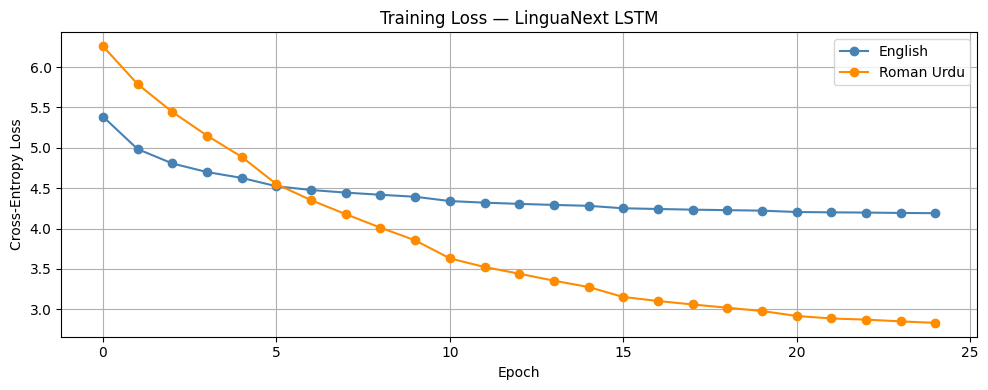

In [30]:
plt.figure(figsize=(10, 4))
plt.plot(en_losses, label="English", color="steelblue", marker="o")
plt.plot(ru_losses, label="Roman Urdu", color="darkorange", marker="o")
plt.title("Training Loss — LinguaNext LSTM")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Save Models

In [31]:
os.makedirs("../model/saved", exist_ok=True)
torch.save(en_model.state_dict(), "/content/english_lstm.pth")
torch.save(ru_model.state_dict(), "/content/roman_urdu_lstm.pth")
print("Models saved.")

Models saved.


### Inference (Top-K Prediction)

In [32]:
def predict_next_words(model, word2idx, idx2word, text, top_k=3, temperature=1.0):
    model.eval()
    tokens = [word2idx.get(w, word2idx["<UNK>"]) for w in clean_text(text).split()]

    if len(tokens) < SEQ_LEN:
        tokens = [word2idx["<PAD>"]] * (SEQ_LEN - len(tokens)) + tokens
    else:
        tokens = tokens[-SEQ_LEN:]

    x = torch.tensor([tokens], dtype=torch.long).to(device)

    with torch.no_grad():
        logits = model(x) / temperature
        probs  = torch.softmax(logits, dim=-1).squeeze()

    top_indices = torch.topk(probs, top_k).indices.tolist()
    return [idx2word[str(i)] if isinstance(list(idx2word.keys())[0], str) else idx2word[i]
            for i in top_indices]

# Test English
print("English predictions:")
print(predict_next_words(en_model, en_word2idx, en_idx2word, "the quick brown fox"))

# Test Roman Urdu
print("\nRoman Urdu predictions:")
print(predict_next_words(ru_model, ru_word2idx, ru_idx2word, "yaar kya baat"))

English predictions:
['<UNK>', 'and', 'unk']

Roman Urdu predictions:
['hoga', 'tha', 'to']
